# Praktikum 1

Langkah 1 - Import Library

In [1]:
# import library
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import seaborn as sns

Langkah 2 - Membuat Data Dummy

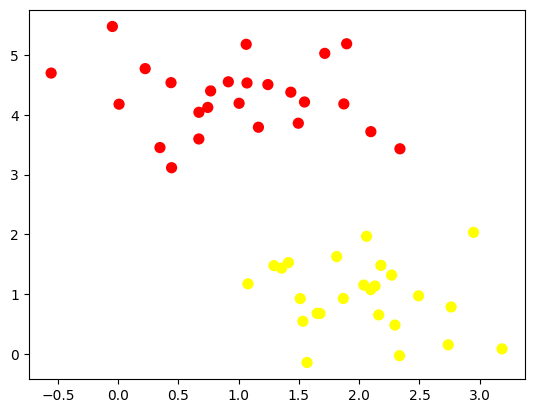

In [2]:
from sklearn.datasets import make_blobs
X, y = make_blobs(n_samples=50, centers=2,
                  random_state=0, cluster_std=0.60)
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')

Langkah 3 - Buat Ilustrasi Garis Pemisah

Langkah 4 - Ilustrasi Margin

(-1.0, 3.5)

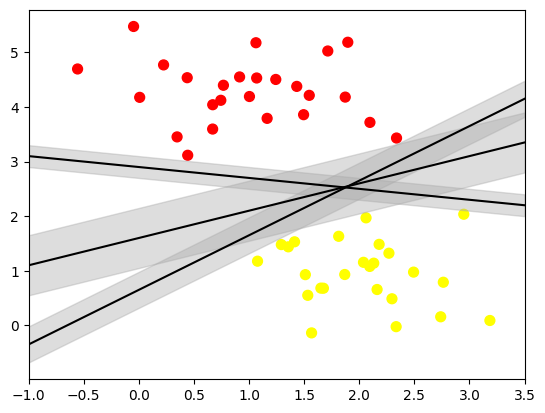

In [3]:
xfit = np.linspace(-1, 3.5)
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')

for m, b, d in [(1, 0.65, 0.33), (0.5, 1.6, 0.55), (-0.2, 2.9, 0.2)]:
    yfit = m * xfit + b
    plt.plot(xfit, yfit, '-k')
    plt.fill_between(xfit, yfit - d, yfit + d, edgecolor='none',
                     color='#AAAAAA', alpha=0.4)

plt.xlim(-1, 3.5)

Langkah 5 - Fitting Model

In [4]:
from sklearn.svm import SVC # "Support vector classifier"
model = SVC(kernel='linear', C=1E10)
model.fit(X, y)

SVC(C=10000000000.0, kernel='linear')

In [5]:
# buat sebuah fungsi untuk menampilkan fitting data

def plot_svc_decision_function(model, ax=None, plot_support=True):

    if ax is None:
        ax = plt.gca()
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()

    # buat grid untuk evaluasi model
    x = np.linspace(xlim[0], xlim[1], 30)
    y = np.linspace(ylim[0], ylim[1], 30)
    Y, X = np.meshgrid(y, x)
    xy = np.vstack([X.ravel(), Y.ravel()]).T
    P = model.decision_function(xy).reshape(X.shape)

    # plot batas dan margin
    ax.contour(X, Y, P, colors='k',
               levels=[-1, 0, 1], alpha=0.5,
               linestyles=['--', '-', '--'])

    # plot support vectors
    if plot_support:
        ax.scatter(model.support_vectors_[:, 0],
                   model.support_vectors_[:, 1],
                   s=300, linewidth=1, facecolors='none');
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)

Lakukan plotting dengan fungsi yang telah dibuat.

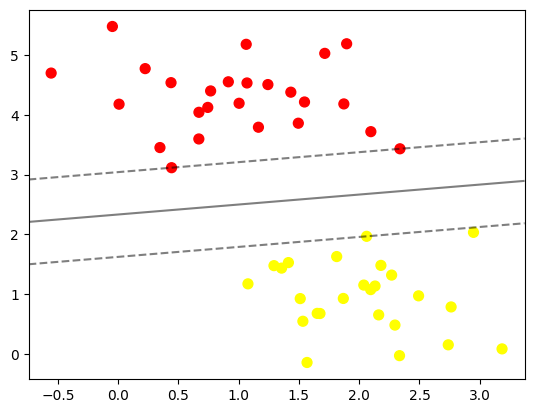

In [6]:
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plot_svc_decision_function(model)

In [7]:
model.support_vectors_

array([[0.44359863, 3.11530945],
       [2.33812285, 3.43116792],
       [2.06156753, 1.96918596]])

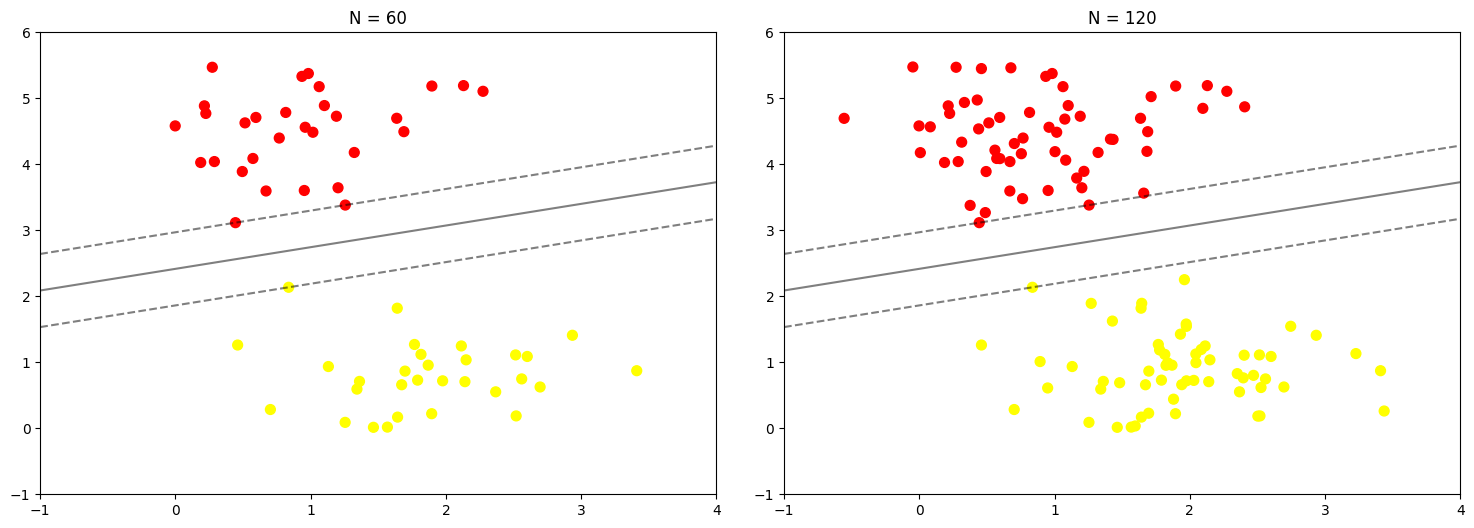

In [8]:
def plot_svm(N=10, ax=None):
    X, y = make_blobs(n_samples=200, centers=2,
                      random_state=0, cluster_std=0.60)
    X = X[:N]
    y = y[:N]
    model = SVC(kernel='linear', C=1E10)
    model.fit(X, y)

    ax = ax or plt.gca()
    ax.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
    ax.set_xlim(-1, 4)
    ax.set_ylim(-1, 6)
    plot_svc_decision_function(model, ax)

fig, ax = plt.subplots(1, 2, figsize=(16, 6))
fig.subplots_adjust(left=0.0625, right=0.95, wspace=0.1)
for axi, N in zip(ax, [60, 120]):
    plot_svm(N, axi)
    axi.set_title('N = {0}'.format(N))

In [9]:
# jumlah data dapat dipilih di antara 10 atau 200 buah data, telihat tidak ada perubahan pada model

from ipywidgets import interact, fixed
interact(plot_svm, N=[10, 200], ax=fixed(None))

interactive(children=(Dropdown(description='N', options=(10, 200), value=10), Output()), _dom_classes=('widget…

<function __main__.plot_svm(N=10, ax=None)>

In [10]:
!pip install ipywidgets

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 35.4 MB/s eta 0:00:00


# Praktikum 2

Langkah 1 - Ilustrasi Data Non-Linier

Langkah 1a - Import Library

In [11]:
# import library
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import seaborn as sns
from sklearn.svm import SVC

Langkah 1b - Buat Kembali Fungsi Plotting

In [12]:
# buat sebuah fungsi untuk menampilkan fitting data

def plot_svc_decision_function(model, ax=None, plot_support=True):

    if ax is None:
        ax = plt.gca()
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()

    # buat grid untuk evaluasi model
    x = np.linspace(xlim[0], xlim[1], 30)
    y = np.linspace(ylim[0], ylim[1], 30)
    Y, X = np.meshgrid(y, x)
    xy = np.vstack([X.ravel(), Y.ravel()]).T
    P = model.decision_function(xy).reshape(X.shape)

    # plot batas dan margin
    ax.contour(X, Y, P, colors='k',
               levels=[-1, 0, 1], alpha=0.5,
               linestyles=['--', '-', '--'])

    # plot support vectors
    if plot_support:
        ax.scatter(model.support_vectors_[:, 0],
                   model.support_vectors_[:, 1],
                   s=300, linewidth=1, facecolors='none');
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)

Langkah 1c - Buat Data Dummy Non-Linier

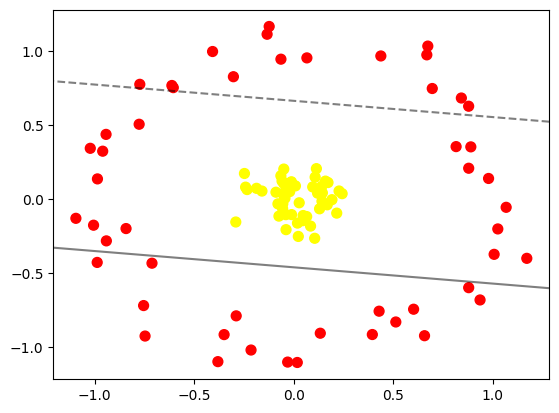

In [13]:
# contoh data tidak terpisah secara linier
from sklearn.datasets import make_circles
X, y = make_circles(100, factor=.1, noise=.1)

clf = SVC(kernel='linear').fit(X, y)

plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plot_svc_decision_function(clf, plot_support=False);

Karena proyeksi radial tidak cukup menggunakan model 2D, maka plot visualisasi diubah menjadi model 3D.

In [14]:
def plot_3D(elev=30, azim=30, X=X, y=y):
    r = np.exp(-X[:, 0] ** 2 - X[:, 1] ** 2) # Calculate radial distance
    fig = plt.figure(figsize=(6, 6))
    ax = plt.subplot(projection='3d')
    ax.scatter3D(X[:, 0], X[:, 1], r, c=y, s=50, cmap='autumn')
    ax.view_init(elev=elev, azim=azim)
    ax.set_xlabel('x')
    ax.set_ylabel('y')
    ax.set_zlabel('r')
    ax.set_title("Proyeksi Radial (3D)")
    plt.show()

interact(plot_3D, elev=[-90, 45, 30, 20, 10], azim=(-180, 180),
         X=fixed(X), y=fixed(y))

interactive(children=(Dropdown(description='elev', index=2, options=(-90, 45, 30, 20, 10), value=30), IntSlide…

<function __main__.plot_3D(elev=30, azim=30, X=array([[-0.24812859,  0.17370933],
       [-0.05085135,  0.10690971],
       [ 0.13295775, -0.90572157],
       [ 0.10710461,  0.14895832],
       [ 0.67320732,  1.03454365],
       [ 0.1677911 , -0.03793123],
       [-0.77714058,  0.50641872],
       [-0.9434461 ,  0.43791756],
       [ 0.87843495,  0.62825142],
       [-0.16013677,  0.05482719],
       [ 0.42847731, -0.75687388],
       [ 0.04689282, -0.11035283],
       [-1.09498174, -0.12927497],
       [ 0.97848917,  0.14005948],
       [-0.02075239,  0.05118895],
       [-0.98794832, -0.42726879],
       [-0.04797833,  0.04499194],
       [-0.71264815, -0.43251775],
       [ 0.60186558, -0.74353079],
       [ 0.84176948,  0.68364752],
       [-0.05617256, -0.06421163],
       [ 0.43721984,  0.96786102],
       [ 0.66823346,  0.97537861],
       [-0.77386886,  0.7762841 ],
       [ 1.0064519 , -0.37265212],
       [ 0.93570655, -0.6808936 ],
       [ 0.14144201, -0.01391026],
       [ 0.12597225,  0.05084104],
       [-0.30357642,  0.82764247],
       [ 0.00806394,  0.08995923],
       [-0.21498168, -1.01928332],
       [-0.06479128,  0.94609028],
       [ 0.06562866,  0.95480841],
       [-0.75475515, -0.71878229],
       [ 0.11947974,  0.0407876 ],
       [-0.98666534,  0.13710571],
       [ 0.12932855, -0.06494436],
       [ 0.65672896, -0.92250796],
       [ 0.06454653, -0.11736473],
       [-0.13427792,  1.11460718],
       [-0.01222962,  0.11766213],
       [ 0.09490201,  0.08285022],
       [ 0.22737167,  0.05539624],
       [-0.01348418,  0.11269859],
       [-0.04456048,  0.00655667],
       [-0.06508454,  0.15844904],
       [ 1.02493775, -0.20099874],
       [ 0.19157066, -0.00329378],
       [ 0.87863167, -0.59791552],
       [ 0.10484782, -0.26416849],
       [-0.23482083,  0.0651098 ],
       [-0.40824256,  0.99787731],
       [ 0.88932207,  0.35355901],
       [ 1.06686132, -0.05484544],
       [-0.28954628, -0.78833532],
       [-0.96028973,  0.32431728],
       [-0.24234063,  0.08140787],
       [-0.61271645,  0.76831027],
       [-0.94191413, -0.28167837],
       [-0.84299821, -0.19845671],
       [-0.38157099, -1.09776256],
       [-0.18744928,  0.0734629 ],
       [-0.0112212 , -0.1042125 ],
       [ 0.69557218,  0.74793119],
       [ 0.01735525, -1.10340083],
       [-0.08970343,  0.04715002],
       [ 0.81537628,  0.35529745],
       [ 0.14049098,  0.08685849],
       [-0.60565971,  0.75384503],
       [-0.05919794,  0.12278365],
       [-0.04036464, -0.10452338],
       [ 0.1589156 ,  0.12216048],
       [-0.05039614,  0.20352549],
       [-0.03095608, -1.100696  ],
       [-0.0139677 ,  0.10693327],
       [-1.00620225, -0.17581123],
       [-0.12382368,  1.1670863 ],
       [ 0.24272004,  0.03733275],
       [ 0.08412712, -0.18178685],
       [ 0.14337551,  0.04252836],
       [ 0.1716686 ,  0.11247222],
       [-0.35026781, -0.91505994],
       [-0.29156115, -0.1541623 ],
       [-0.07478284, -0.11437813],
       [ 0.51247034, -0.82979038],
       [-0.0391019 , -0.20585481],
       [-1.02272461,  0.34385719],
       [ 0.02704704, -0.02429685],
       [-0.07978974, -0.0314625 ],
       [ 0.04505575, -0.14512712],
       [ 0.02254373, -0.25166754],
       [ 0.11341367,  0.20644176],
       [-0.05537152, -0.03121802],
       [ 0.01835626, -0.16150303],
       [ 0.39445093, -0.91454394],
       [-0.74745848, -0.92482805],
       [ 0.87867754,  0.20912081],
       [ 0.21559829, -0.09418785],
       [-0.04951572,  0.024171  ],
       [ 1.17060025, -0.39965461]]), y=array([1, 1, 0, 1, 0, 1, 0, 0, 0, 1, 0, 1, 0, 0, 1, 0, 1, 0, 0, 0, 1, 0,
       0, 0, 0, 0, 1, 1, 0, 1, 0, 0, 0, 0, 1, 0, 1, 0, 1, 0, 1, 1, 1, 1,
       1, 1, 0, 1, 0, 1, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0, 1,
       0, 1, 0, 1, 1, 1, 1, 0, 1, 0, 0, 1, 1, 1, 1, 0, 1, 1, 0, 1, 0, 1,
       1, 1, 1, 1, 1, 1, 0, 0, 0, 1, 1, 0]))>

Langkah 2 - Fitting Model

In [15]:
clf = SVC(kernel='rbf', C=1E6)
clf.fit(X, y)

SVC(C=1000000.0)

Plot hasil decision boundaries dari kernel RBF

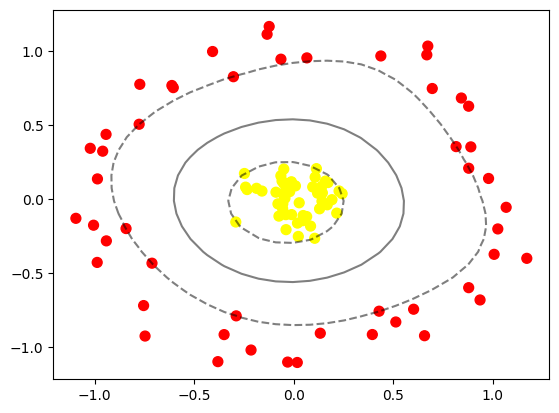

In [16]:
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plot_svc_decision_function(clf)
plt.scatter(clf.support_vectors_[:, 0], clf.support_vectors_[:, 1],
            s=300, lw=1, facecolors='none')

# Praktikum 3

Langkah 1 - Import Library dan Buat Fungsi Plotting

In [17]:
# import library
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import seaborn as sns
from sklearn.svm import SVC
from sklearn.datasets import make_blobs

In [18]:
# buat sebuah fungsi untuk menampilkan fitting data

def plot_svc_decision_function(model, ax=None, plot_support=True):

    if ax is None:
        ax = plt.gca()
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()

    # buat grid untuk evaluasi model
    x = np.linspace(xlim[0], xlim[1], 30)
    y = np.linspace(ylim[0], ylim[1], 30)
    Y, X = np.meshgrid(y, x)
    xy = np.vstack([X.ravel(), Y.ravel()]).T
    P = model.decision_function(xy).reshape(X.shape)

    # plot batas dan margin
    ax.contour(X, Y, P, colors='k',
               levels=[-1, 0, 1], alpha=0.5,
               linestyles=['--', '-', '--'])

    # plot support vectors
    if plot_support:
        ax.scatter(model.support_vectors_[:, 0],
                   model.support_vectors_[:, 1],
                   s=300, linewidth=1, facecolors='none');
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)

Langkah 2 - Buat Data Dummy



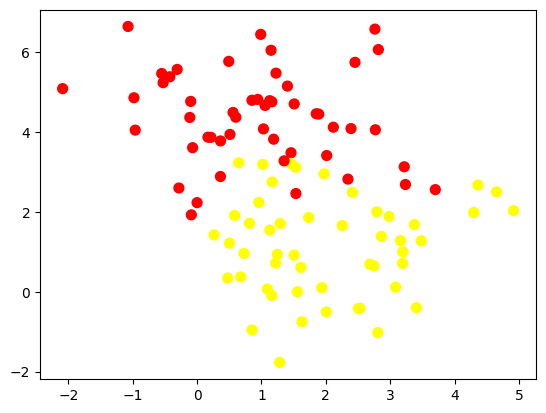

In [19]:
X, y = make_blobs(n_samples=100, centers=2,
                  random_state=0, cluster_std=1.2)
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')

Langkah 3 - Analisis Dampak Tunning

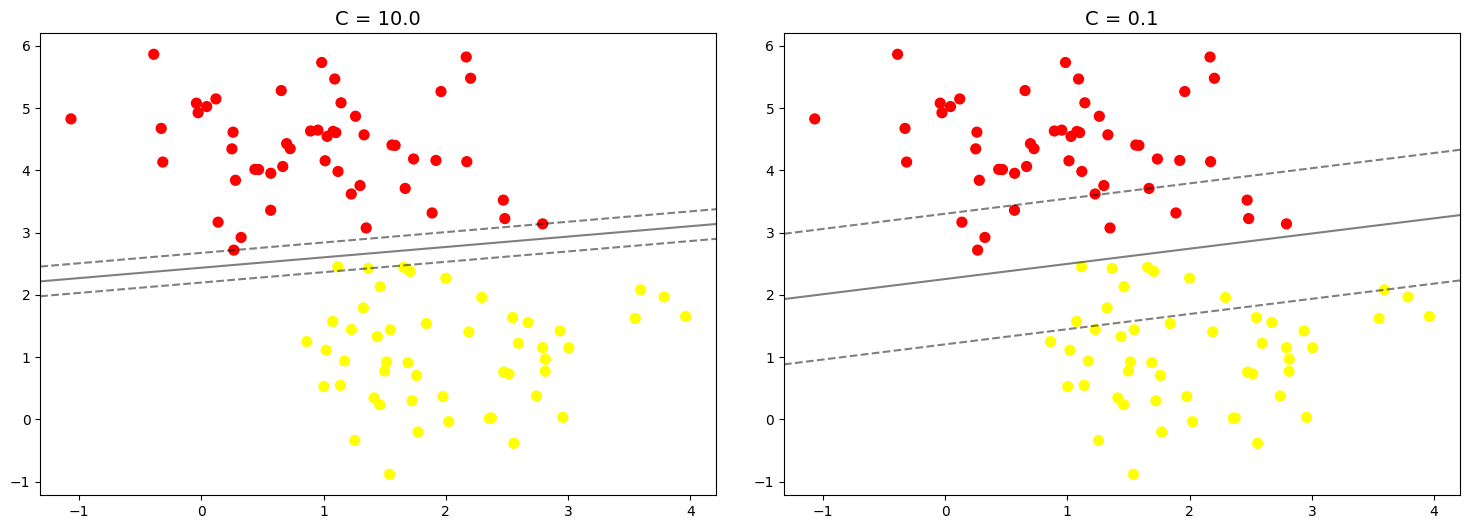

In [20]:
X, y = make_blobs(n_samples=100, centers=2,
                  random_state=0, cluster_std=0.8)

fig, ax = plt.subplots(1, 2, figsize=(16, 6))
fig.subplots_adjust(left=0.0625, right=0.95, wspace=0.1)

for axi, C in zip(ax, [10.0, 0.1]):
    model = SVC(kernel='linear', C=C).fit(X, y)
    axi.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
    plot_svc_decision_function(model, axi)
    axi.scatter(model.support_vectors_[:, 0],
                model.support_vectors_[:, 1],
                s=300, lw=1, facecolors='none');
    axi.set_title('C = {0:.1f}'.format(C), size=14)

# Praktikum 4

Langkah 0 - Unduh Dataset

In [21]:
from sklearn.datasets import fetch_lfw_people
faces = fetch_lfw_people(min_faces_per_person=60)
print(faces.target_names)
print(len(faces.target_names))
print(faces.images.shape)

['Ariel Sharon' 'Colin Powell' 'Donald Rumsfeld' 'George W Bush'
 'Gerhard Schroeder' 'Hugo Chavez' 'Junichiro Koizumi' 'Tony Blair']
8
(1348, 62, 47)


Langkah 1 - Inspeksi Citra Wajah

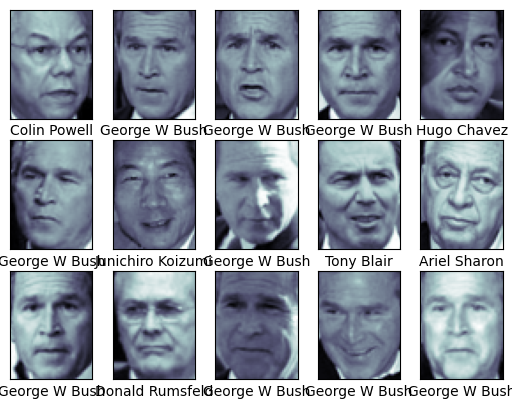

In [22]:
# contoh wajah yang digunakan
from matplotlib import pyplot as plt

fig, ax = plt.subplots(3, 5)
for i, axi in enumerate(ax.flat):
    axi.imshow(faces.images[i], cmap='bone')
    axi.set(xticks=[], yticks=[],
            xlabel=faces.target_names[faces.target[i]])

Langkah 2 - Pra Pengolahan Data

In [23]:
from sklearn.svm import SVC
from sklearn.decomposition import PCA as RandomizedPCA
from sklearn.pipeline import make_pipeline

pca = RandomizedPCA(n_components=150, whiten=True, random_state=42)
svc = SVC(kernel='rbf', class_weight='balanced')

# Pipeline digunakan untuk melakukan proses secara bertahap dalam
# 1 eksekusi fungsi secara langsung
model = make_pipeline(pca, svc)

Langkah 3 - Split Data

In [24]:
# pemisahan data training dan data testing

from sklearn.model_selection import train_test_split
Xtrain, Xtest, ytrain, ytest = train_test_split(faces.data, faces.target, random_state=42)

Langkah 4 - Pembuatan Model + Tunning

In [25]:
from sklearn.model_selection import GridSearchCV
param_grid = {'svc__C': [1, 5, 10, 50],
              'svc__gamma': [0.0001, 0.0005, 0.001, 0.005]}
grid = GridSearchCV(model, param_grid)

%time grid.fit(Xtrain, ytrain)
print(grid.best_params_)
print(grid.best_score_)

CPU times: user 2min 5s, sys: 237 ms, total: 2min 6s
Wall time: 1min 17s
{'svc__C': 5, 'svc__gamma': 0.001}
0.828893332683022


In [26]:
model = grid.best_estimator_
yfit = model.predict(Xtest)

Langkah 5 - Cek Hasil Prediksi

Text(0.5, 0.98, 'Predicted Names; Incorrect Labels in Red')

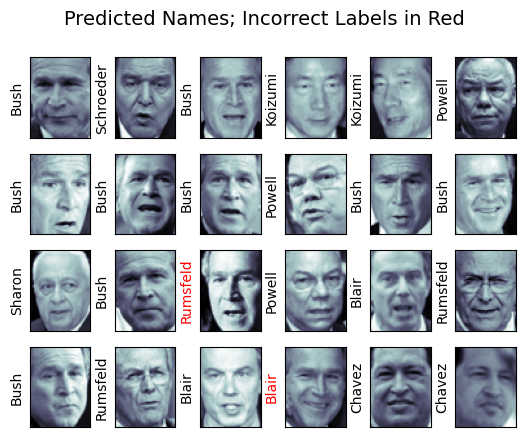

In [27]:
# hasil label pada data testing

fig, ax = plt.subplots(4, 6)
for i, axi in enumerate(ax.flat):
    axi.imshow(Xtest[i].reshape(62, 47), cmap='bone')
    axi.set(xticks=[], yticks=[])
    axi.set_ylabel(faces.target_names[yfit[i]].split()[-1],
                   color='black' if yfit[i] == ytest[i] else 'red')
fig.suptitle('Predicted Names; Incorrect Labels in Red', size=14)

Langkah 6 - Cek Performansi

In [28]:
from sklearn.metrics import classification_report
print(classification_report(ytest, yfit,
                            target_names=faces.target_names))

                   precision    recall  f1-score   support

     Ariel Sharon       0.65      0.87      0.74        15
     Colin Powell       0.83      0.88      0.86        68
  Donald Rumsfeld       0.70      0.84      0.76        31
    George W Bush       0.97      0.80      0.88       126
Gerhard Schroeder       0.76      0.83      0.79        23
      Hugo Chavez       0.93      0.70      0.80        20
Junichiro Koizumi       0.86      1.00      0.92        12
       Tony Blair       0.82      0.98      0.89        42

         accuracy                           0.85       337
        macro avg       0.82      0.86      0.83       337
     weighted avg       0.86      0.85      0.85       337



Selanjutnya, kita dapat menggunakan confusion matrix untuk mengetahui label label yang terklasifikasi  dengan benar dan tidak.

Text(113.92222222222219, 0.5, 'predicted label')

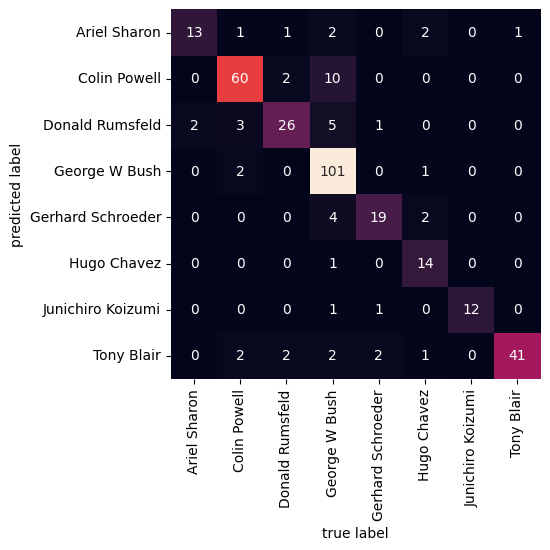

In [29]:
# bentuk confusion matrix
from sklearn.metrics import confusion_matrix
import seaborn as sns

mat = confusion_matrix(ytest, yfit)
sns.heatmap(mat.T, square=True, annot=True, fmt='d', cbar=False,
            xticklabels=faces.target_names,
            yticklabels=faces.target_names)
plt.xlabel('true label')
plt.ylabel('predicted label')

# Praktikum 5

Langkah 0 - Import Library

In [30]:
# Import Required Libraries
from pathlib import Path
import matplotlib.image as mpimg
import matplotlib.pyplot as plt
import cv2
import random
import numpy as np
import pandas as pd

Lakukan ekstraksi data gambar, kemudian definisikan lokasi gambar. Pada contoh ini, folder gambar berlokasi sama dengan lokasi file python.

In [31]:
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [32]:
# Image directories
train_dir = "/content/drive/MyDrive/Dataset Mesin/Images Mesin/images/training"
test_dir = "/content/drive/MyDrive/Dataset Mesin/Images Mesin/images/test"

Langkah 1 - Load Data dan Visualisasikan

In [33]:
def load_dataset(img_dir):
    p = Path(img_dir)
    dirs = p.glob('*')

    img_list = []

    for dir in dirs:
        label = str(dir).split('/')[-1]
        for file in dir.glob('*.jpg'):
            img = mpimg.imread(file)

            if not img is None:
                img_list.append((img, label))

    return img_list

Load gambar training

In [34]:
# Load training data
train_img = load_dataset(train_dir)

Lakukan pengecekan pada salah satu data pada list. List harus berisi tuple dengan dua data, yaitu data gambar dan label dari gambar.

In [35]:
# Check the first data
# It should be a tuple consist of arrays of image and image labels
train_img[0]

(array([[[22, 24, 23],
         [20, 22, 21],
         [18, 20, 19],
         ...,
         [15, 16, 10],
         [15, 16, 10],
         [15, 16, 10]],
 
        [[22, 24, 23],
         [20, 22, 21],
         [18, 20, 19],
         ...,
         [15, 16, 10],
         [15, 16, 10],
         [15, 16, 10]],
 
        [[22, 24, 23],
         [20, 22, 21],
         [19, 21, 20],
         ...,
         [15, 16, 10],
         [15, 16, 10],
         [15, 16, 10]],
 
        ...,
 
        [[11, 11, 11],
         [10, 10, 10],
         [ 9,  9,  9],
         ...,
         [ 6,  9,  0],
         [ 6,  9,  0],
         [ 6,  9,  0]],
 
        [[11, 11, 11],
         [10, 10, 10],
         [ 9,  9,  9],
         ...,
         [ 6,  9,  0],
         [ 6,  9,  0],
         [ 6,  9,  0]],
 
        [[11, 11, 11],
         [10, 10, 10],
         [ 9,  9,  9],
         ...,
         [ 6,  9,  0],
         [ 6,  9,  0],
         [ 6,  9,  0]]], dtype=uint8),
 'night')

Cek ukuran gambar secara acak

In [36]:
# Random size checking
pick_random = np.random.randint(0, len(train_img))

# Check img size
print(f'Image {pick_random}')
print(train_img[pick_random][0].shape)

Image 164
(469, 640, 3)


Tampilkan gambar untuk inspeksi secara visual. Buatlah fungsi untuk membantu memvisualkan gambar

In [37]:
# Function to Visualize
def random_img_viz(img_list):
    rand_num = np.random.randint(0, len(img_list))

    img = img_list[rand_num][0]
    label = img_list[rand_num][1]
    label_str = 'day' if label == 1 else 'night'

    plt.imshow(img)
    print(f'Shape\t: {img.shape}')
    print(f'Label\t: {label}')

Lakukan visualisasi gambar secara acak

Shape	: (593, 800, 3)
Label	: day


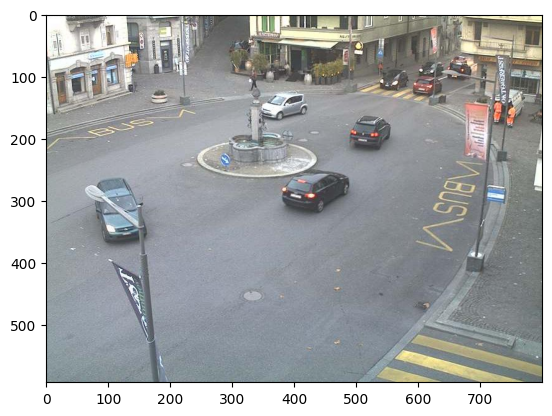

In [38]:
random_img_viz(train_img)

# Tugas Praktikum

1. Buatlah model SVM dengan menggunakan data voice.csv dengan ketentuan,

a. Split data dengan rasio 70:30 dan 80:20 untuk setiap model yang akan dibangun.
* Gunakan model dengan kernel linier.
* Gunakan model dengan kernel polynomial.
* Gunakan model dengan kernel RBF.

b. Tabulasikan performansi setiap split dan kernel berdasarkan metrik akurasi.

2. Gunakan data pada praktikum 5 untuk membuat model klasifikasi siang dan malam menggunakan SVM dengan kernel RBF menggunakan fitur histrogram. Gunakan rasio 80:20. Anda dapat bereksperimen dengan hyperparameter tunning dari kernel RBF. Catat performansi akurasinya!


Langkah 1 — Import Library

In [39]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score


Langkah 2 — Baca Dataset

In [40]:
# Membaca file voice.csv
df = pd.read_csv("/content/drive/MyDrive/Dataset Mesin/voice.csv")

# Menampilkan 5 data pertama
print(df.head())


   meanfreq        sd    median       Q25       Q75       IQR       skew  \
0  0.059781  0.064241  0.032027  0.015071  0.090193  0.075122  12.863462   
1  0.066009  0.067310  0.040229  0.019414  0.092666  0.073252  22.423285   
2  0.077316  0.083829  0.036718  0.008701  0.131908  0.123207  30.757155   
3  0.151228  0.072111  0.158011  0.096582  0.207955  0.111374   1.232831   
4  0.135120  0.079146  0.124656  0.078720  0.206045  0.127325   1.101174   

          kurt    sp.ent       sfm  ...  centroid   meanfun    minfun  \
0   274.402906  0.893369  0.491918  ...  0.059781  0.084279  0.015702   
1   634.613855  0.892193  0.513724  ...  0.066009  0.107937  0.015826   
2  1024.927705  0.846389  0.478905  ...  0.077316  0.098706  0.015656   
3     4.177296  0.963322  0.727232  ...  0.151228  0.088965  0.017798   
4     4.333713  0.971955  0.783568  ...  0.135120  0.106398  0.016931   

     maxfun   meandom    mindom    maxdom   dfrange   modindx  label  
0  0.275862  0.007812  0.007812  

Langkah 3 — Pisahkan Fitur dan Label

In [41]:
# Pisahkan fitur dan label
X = df.drop('label', axis=1)
y = df['label'].map({'male': 0, 'female': 1})  # ubah ke angka


Langkah 4 — Normalisasi Data

In [42]:
# Standarisasi agar semua fitur memiliki skala yang sama
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


Langkah 5 — Fungsi untuk Uji SVM

In [43]:
def evaluate_svm_models(X, y, test_size):
    # Split data
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=test_size, random_state=42)

    # --- Kernel Linear ---
    svm_linear = SVC(kernel='linear')
    svm_linear.fit(X_train, y_train)
    acc_linear = accuracy_score(y_test, svm_linear.predict(X_test))

    # --- Kernel Polynomial ---
    svm_poly = SVC(kernel='poly')
    svm_poly.fit(X_train, y_train)
    acc_poly = accuracy_score(y_test, svm_poly.predict(X_test))

    # --- Kernel RBF ---
    svm_rbf = SVC(kernel='rbf')
    svm_rbf.fit(X_train, y_train)
    acc_rbf = accuracy_score(y_test, svm_rbf.predict(X_test))

    return {
        'Split Rasio': f"{int((1-test_size)*100)}:{int(test_size*100)}",
        'Linear': acc_linear,
        'Polynomial': acc_poly,
        'RBF': acc_rbf
    }


Langkah 6 — Jalankan untuk 70:30 dan 80:20

In [44]:
hasil = []
hasil.append(evaluate_svm_models(X_scaled, y, test_size=0.3))
hasil.append(evaluate_svm_models(X_scaled, y, test_size=0.2))

df_hasil = pd.DataFrame(hasil)
print(df_hasil)


  Split Rasio    Linear  Polynomial       RBF
0       70:30  0.970557    0.956887  0.981073
1       80:20  0.976341    0.970032  0.982650


In [46]:
# ===========================================
#  Import library
# ===========================================
import cv2
import os
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt

# ===========================================
# Fungsi ekstraksi fitur histogram (HSV - channel V)
# ===========================================
def load_histogram_features(img_dir):
    features = []
    labels = []

    for label in os.listdir(img_dir):
        folder_path = os.path.join(img_dir, label)
        if not os.path.isdir(folder_path):
            continue

        for img_file in os.listdir(folder_path):
            img_path = os.path.join(folder_path, img_file)
            img = cv2.imread(img_path)
            if img is None:
                continue

            # Konversi ke HSV dan ambil channel V (brightness)
            hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
            v_channel = hsv[:, :, 2]

            # Hitung histogram brightness
            hist = cv2.calcHist([v_channel], [0], None, [32], [0, 256])
            hist = cv2.normalize(hist, hist).flatten()

            # Simpan fitur dan label
            features.append(hist)
            labels.append(1 if label.lower() == 'day' else 0)

    return np.array(features), np.array(labels)

# ===========================================
#  Load dataset
# ===========================================
train_dir = "/content/drive/MyDrive/Dataset Mesin/Images Mesin/images/training"

X, y = load_histogram_features(train_dir)
print("Jumlah data:", len(X))

# ===========================================
#  Split data 80:20
# ===========================================
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# ===========================================
# Hyperparameter tuning untuk SVM RBF
# ===========================================
best_acc = 0
best_C = None
best_gamma = None

for C in [0.1, 1, 10, 100]:
    for gamma in [0.01, 0.1, 1]:
        model = SVC(kernel='rbf', C=C, gamma=gamma)
        model.fit(X_train, y_train)
        acc = accuracy_score(y_test, model.predict(X_test))
        print(f"C={C}, gamma={gamma} → Akurasi = {acc:.4f}")

        if acc > best_acc:
            best_acc = acc
            best_C = C
            best_gamma = gamma

# ===========================================
# Tampilkan hasil terbaik
# ===========================================
print("\n Model Terbaik (RBF Kernel)")
print(f"Parameter: C={best_C}, gamma={best_gamma}")
print(f"Akurasi terbaik: {best_acc:.4f}")



Jumlah data: 240
C=0.1, gamma=0.01 → Akurasi = 0.7083
C=0.1, gamma=0.1 → Akurasi = 0.7292
C=0.1, gamma=1 → Akurasi = 0.9583
C=1, gamma=0.01 → Akurasi = 0.7083
C=1, gamma=0.1 → Akurasi = 0.9792
C=1, gamma=1 → Akurasi = 0.9792
C=10, gamma=0.01 → Akurasi = 0.9792
C=10, gamma=0.1 → Akurasi = 0.9583
C=10, gamma=1 → Akurasi = 1.0000
C=100, gamma=0.01 → Akurasi = 0.9583
C=100, gamma=0.1 → Akurasi = 1.0000
C=100, gamma=1 → Akurasi = 1.0000

 Model Terbaik (RBF Kernel)
Parameter: C=10, gamma=1
Akurasi terbaik: 1.0000
